# 🏥 The MedFit Story: Understanding Distributions, Probabilities & Relationships in Data

---

## The Setup

You've just been hired as the **first Data Scientist** at **MedFit Analytics** — a health-tech startup building a personalized fitness and wellness app.

MedFit has been collecting health data from thousands of users: their **heights, weights, resting heart rates, daily step counts, workout frequency**, and more. The product team, the marketing team, and even the CEO keep coming to you with questions like:

> *"What fraction of our users are taller than 6 feet?"*
>
> *"If someone has a high resting heart rate, do they also tend to have fewer daily steps?"*
>
> *"We ran a small pilot with 12 users — can we trust the results?"*

To answer these questions, you don't need a PhD in mathematics. You need **intuition** about how data behaves, how to ask probability questions, and how to be careful with small samples.

**That's exactly what this notebook will teach you.**

---

### 🗺️ Our Roadmap

| Chapter | What You'll Learn | The Business Question |
|---|---|---|
| **1** | Gaussian (Normal) Distribution | *"What does 'typical' look like for our users?"* |
| **2** | PDF, PMF, CDF, PPF | *"How do we answer probability questions about our users?"* |
| **3** | Covariance Matrix | *"Which health metrics move together?"* |
| **4** | Student's T Distribution | *"Can we trust results from a tiny pilot study?"* |

Let's load our data and begin the story.


## 📦 Chapter 0: Setting the Stage — Our MedFit User Data

Before we dive in, let's generate our MedFit user dataset. In a real company, this would come from your database. Here, we'll create **realistic synthetic health data** for 5,000 users that mimics real-world patterns.

> **Why synthetic?** Because the patterns are what matter — and we can control them to make learning crystal clear.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set a clean, modern visual style
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'figure.dpi': 100
})

MEDFIT_BLUE = '#2196F3'
MEDFIT_GREEN = '#4CAF50'
MEDFIT_ORANGE = '#FF9800'
MEDFIT_RED = '#F44336'
MEDFIT_PURPLE = '#9C27B0'

np.random.seed(42)  # For reproducibility

n_users = 5000

# --- Generate realistic, correlated health data ---
# Heights in cm (mean ~170 cm with natural variation)
heights = np.random.normal(loc=170, scale=10, size=n_users)

# Weights — correlated with height (taller people tend to weigh more)
weights = 0.8 * heights + np.random.normal(loc=-60, scale=8, size=n_users)

# Resting heart rate (bpm) — slightly inversely correlated with fitness
resting_hr = np.random.normal(loc=72, scale=10, size=n_users)

# Daily steps — inversely correlated with resting HR (fitter people walk more)
daily_steps = 12000 - 80 * resting_hr + np.random.normal(loc=0, scale=2000, size=n_users)
daily_steps = np.clip(daily_steps, 1000, 25000)

# Weekly workout sessions (discrete: 0-7) — correlated with daily steps
workout_prob = (daily_steps - daily_steps.min()) / (daily_steps.max() - daily_steps.min())
weekly_workouts = np.array([np.random.binomial(7, min(p * 0.8 + 0.1, 0.95)) for p in workout_prob])

# Build the DataFrame
users = pd.DataFrame({
    'user_id': [f'MF-{i:04d}' for i in range(1, n_users + 1)],
    'height_cm': np.round(heights, 1),
    'weight_kg': np.round(weights, 1),
    'resting_hr_bpm': np.round(resting_hr, 0).astype(int),
    'daily_steps': np.round(daily_steps, 0).astype(int),
    'weekly_workouts': weekly_workouts
})

print(f"✅ MedFit dataset loaded: {len(users):,} users, {users.shape[1]} features\n")
print(users.head(10).to_string(index=False))
print(f"\n--- Quick Summary ---")
print(users.describe().round(1).to_string())


✅ MedFit dataset loaded: 5,000 users, 6 features

user_id  height_cm  weight_kg  resting_hr_bpm  daily_steps  weekly_workouts
MF-0001      175.0       76.6              65         6496                1
MF-0002      168.6       71.3              69         6419                6
MF-0003      176.5       66.8              66         6846                4
MF-0004      185.2       85.5              73         8045                2
MF-0005      167.7       80.0              84         3788                2
MF-0006      167.7       63.9              64         5164                1
MF-0007      185.8       97.0              82         7913                6
MF-0008      177.7       86.0              64         5940                4
MF-0009      165.3       66.4              64         4392                2
MF-0010      175.4       79.2              80         4615                1

--- Quick Summary ---
       height_cm  weight_kg  resting_hr_bpm  daily_steps  weekly_workouts
count     5000.0 

---

## 📊 Chapter 1: The Bell Curve of Life — The Gaussian (Normal) Distribution

### The Business Question

The MedFit product team walks up to your desk:

> *"Hey, we're designing the UI for our height-based recommendations. We need to understand what 'typical' looks like. Are most users clustered around a certain height, or are they spread all over the place?"*

Great question. Let's look at the data.


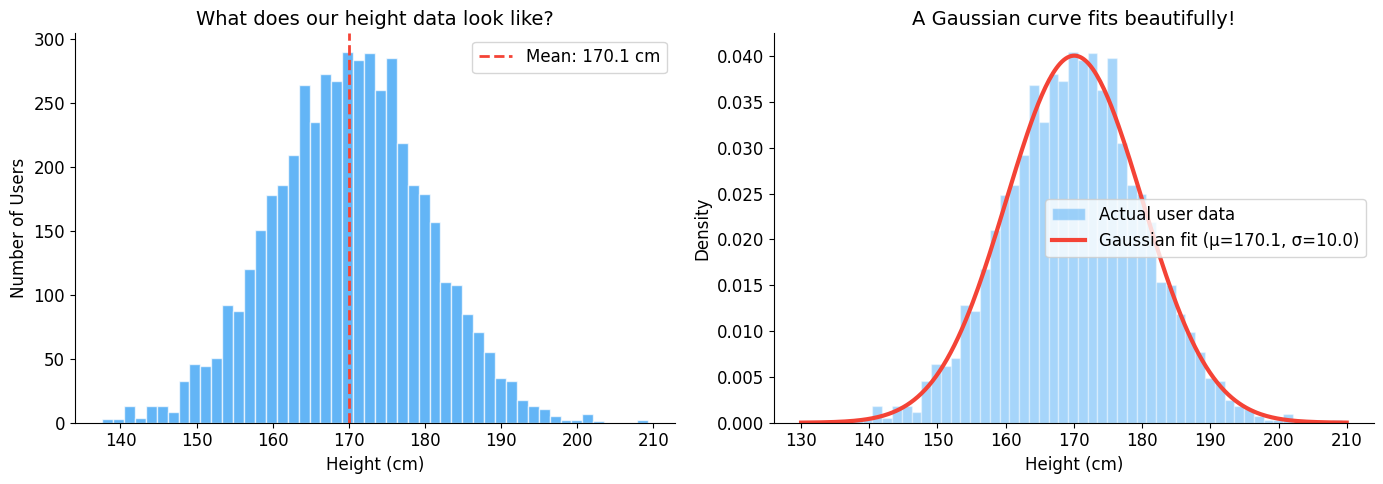

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Raw histogram
axes[0].hist(users['height_cm'], bins=50, color=MEDFIT_BLUE, alpha=0.7, edgecolor='white')
axes[0].set_xlabel('Height (cm)')
axes[0].set_ylabel('Number of Users')
axes[0].set_title('What does our height data look like?')
axes[0].axvline(users['height_cm'].mean(), color=MEDFIT_RED, linestyle='--', linewidth=2, label=f"Mean: {users['height_cm'].mean():.1f} cm")
axes[0].legend()

# Right: The same data with a Gaussian curve overlaid
from scipy.stats import norm

x = np.linspace(130, 210, 300)
mu, sigma = users['height_cm'].mean(), users['height_cm'].std()

axes[1].hist(users['height_cm'], bins=50, density=True, color=MEDFIT_BLUE, alpha=0.4, edgecolor='white', label='Actual user data')
axes[1].plot(x, norm.pdf(x, mu, sigma), color=MEDFIT_RED, linewidth=3, label=f'Gaussian fit (μ={mu:.1f}, σ={sigma:.1f})')
axes[1].set_xlabel('Height (cm)')
axes[1].set_ylabel('Density')
axes[1].set_title('A Gaussian curve fits beautifully!')
axes[1].legend()

plt.tight_layout()
plt.show()


### 💡 So, What IS a Gaussian Distribution?

Look at the shape on the right. That smooth, symmetric, bell-shaped curve is called a **Gaussian** (or **Normal**) distribution. It's one of the most important ideas in all of data science, and here's the beautiful part:

**Nature loves this shape.**

Heights, blood pressure, measurement errors, exam scores, shoe sizes — when you measure *enough* of almost anything biological or physical, this bell shape tends to show up. It's not a coincidence; it's a deep mathematical truth called the **Central Limit Theorem** (a story for another day).

### The Two Numbers That Define Everything

A Gaussian distribution is completely described by just **two numbers**:

| Symbol | Name | What it means (intuitively) |
|---|---|---|
| **μ** (mu) | **Mean** | The *center* of the bell — where most people cluster |
| **σ** (sigma) | **Standard Deviation** | The *width* of the bell — how spread out people are |

Think of it this way:
- **μ** tells you *where* the bell sits on the number line
- **σ** tells you *how fat or skinny* the bell is

A small σ means everyone is bunched tightly around the mean (like heights in a specific age group). A large σ means the data is spread way out (like annual incomes in a country).


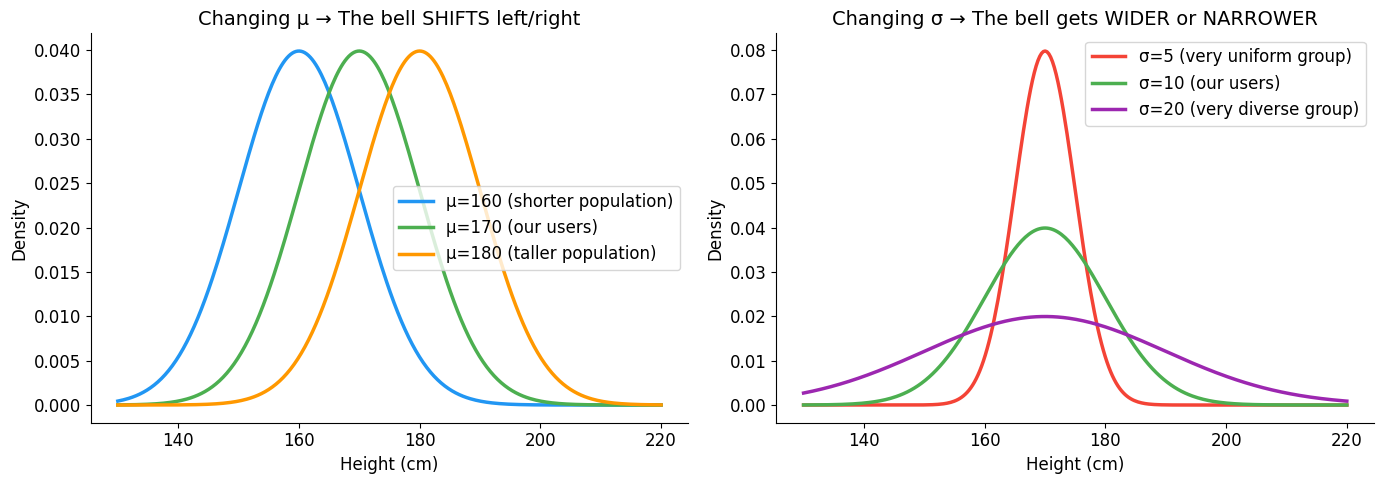

In [3]:
# Visual: How mu and sigma shape the Gaussian

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.linspace(130, 220, 300)

# Effect of changing mu (center shifts)
for mu_val, color, label in [(160, MEDFIT_BLUE, 'μ=160 (shorter population)'),
                              (170, MEDFIT_GREEN, 'μ=170 (our users)'),
                              (180, MEDFIT_ORANGE, 'μ=180 (taller population)')]:
    axes[0].plot(x, norm.pdf(x, mu_val, 10), color=color, linewidth=2.5, label=label)
axes[0].set_title('Changing μ → The bell SHIFTS left/right')
axes[0].set_xlabel('Height (cm)')
axes[0].set_ylabel('Density')
axes[0].legend()

# Effect of changing sigma (bell gets wider/narrower)
for sigma_val, color, label in [(5, MEDFIT_RED, 'σ=5 (very uniform group)'),
                                 (10, MEDFIT_GREEN, 'σ=10 (our users)'),
                                 (20, MEDFIT_PURPLE, 'σ=20 (very diverse group)')]:
    axes[1].plot(x, norm.pdf(x, 170, sigma_val), color=color, linewidth=2.5, label=label)
axes[1].set_title('Changing σ → The bell gets WIDER or NARROWER')
axes[1].set_xlabel('Height (cm)')
axes[1].set_ylabel('Density')
axes[1].legend()

plt.tight_layout()
plt.show()


### 🎯 The 68-95-99.7 Rule (Your New Best Friend)

Here's a handy rule of thumb that every data scientist carries in their back pocket:

- **~68%** of data falls within **1σ** of the mean
- **~95%** of data falls within **2σ** of the mean
- **~99.7%** of data falls within **3σ** of the mean

Let's verify this with our actual MedFit height data:


Our MedFit height data:  μ = 170.1 cm,  σ = 10.0 cm

  Within 1σ (160.1 to 180.0 cm): 68.7% of users  (theory says ~68%)
  Within 2σ (150.1 to 190.0 cm): 95.3% of users  (theory says ~95%)
  Within 3σ (140.2 to 200.0 cm): 99.7% of users  (theory says ~99.7%)


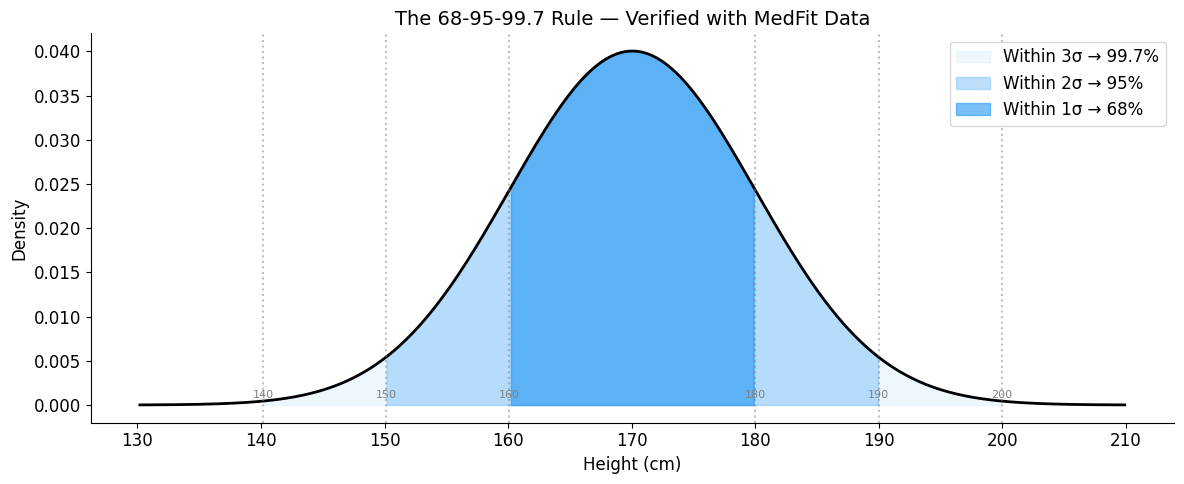

In [4]:
mu = users['height_cm'].mean()
sigma = users['height_cm'].std()

within_1 = ((users['height_cm'] >= mu - sigma) & (users['height_cm'] <= mu + sigma)).mean() * 100
within_2 = ((users['height_cm'] >= mu - 2*sigma) & (users['height_cm'] <= mu + 2*sigma)).mean() * 100
within_3 = ((users['height_cm'] >= mu - 3*sigma) & (users['height_cm'] <= mu + 3*sigma)).mean() * 100

print(f"Our MedFit height data:  μ = {mu:.1f} cm,  σ = {sigma:.1f} cm\n")
print(f"  Within 1σ ({mu-sigma:.1f} to {mu+sigma:.1f} cm): {within_1:.1f}% of users  (theory says ~68%)")
print(f"  Within 2σ ({mu-2*sigma:.1f} to {mu+2*sigma:.1f} cm): {within_2:.1f}% of users  (theory says ~95%)")
print(f"  Within 3σ ({mu-3*sigma:.1f} to {mu+3*sigma:.1f} cm): {within_3:.1f}% of users  (theory says ~99.7%)")

# Visualization
fig, ax = plt.subplots(figsize=(12, 5))
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 500)

ax.plot(x, norm.pdf(x, mu, sigma), color='black', linewidth=2)

# Shade regions
colors_bands = [(3, '#E3F2FD', '99.7%'), (2, '#90CAF9', '95%'), (1, '#2196F3', '68%')]
for n_sig, color, label in colors_bands:
    mask = (x >= mu - n_sig*sigma) & (x <= mu + n_sig*sigma)
    ax.fill_between(x[mask], norm.pdf(x[mask], mu, sigma), alpha=0.6, color=color, label=f'Within {n_sig}σ → {label}')

ax.set_xlabel('Height (cm)')
ax.set_ylabel('Density')
ax.set_title('The 68-95-99.7 Rule — Verified with MedFit Data')
ax.legend(loc='upper right')

# Annotate sigma boundaries
for n_sig in [1, 2, 3]:
    for sign in [-1, 1]:
        val = mu + sign * n_sig * sigma
        ax.axvline(val, color='gray', linestyle=':', alpha=0.5)
        ax.text(val, ax.get_ylim()[1] * 0.02, f'{val:.0f}', ha='center', fontsize=8, color='gray')

plt.tight_layout()
plt.show()


### ✅ Chapter 1 Takeaway

> **The Gaussian distribution is nature's favorite shape.** It shows up everywhere in real-world data. It's defined entirely by its **center (μ)** and its **spread (σ)**. The 68-95-99.7 rule gives you an instant intuition for how likely different values are.

---


## 📈 Chapter 2: Answering Probability Questions — PDF, PMF, CDF, and PPF

Now that we understand the *shape* of our data, the product team starts asking **probability questions**:

> 1. *"What fraction of users are between 165 cm and 175 cm tall?"*
> 2. *"Below what height do 90% of our users fall?"*
> 3. *"How many users do exactly 3 workouts per week?"*

Each of these questions requires a different **probability tool**. Let's meet them one by one.

---

### 🔹 2.1 — PDF: The Probability Density Function (for Continuous Data)

**The question:** *"How likely is a user to be around a certain height?"*

When we have **continuous** data (heights, weights, heart rates — things measured on a smooth scale), we use the **PDF** — the Probability **Density** Function.

Here's the critical insight that trips up a lot of people:

> ⚠️ **For continuous data, the probability of any EXACT value is zero.**
>
> Think about it: what's the probability that someone is *exactly* 170.0000000... cm tall? Essentially zero. There are infinitely many possible values.

So the PDF doesn't give you a probability directly — it gives you a **density**. Think of density like *concentration*: **where the curve is tall, values are densely packed; where it's short, values are sparse.**

To get an actual probability, you need the **area under the curve** between two points. That's where the CDF comes in (next section). But first, let's visualize the PDF:


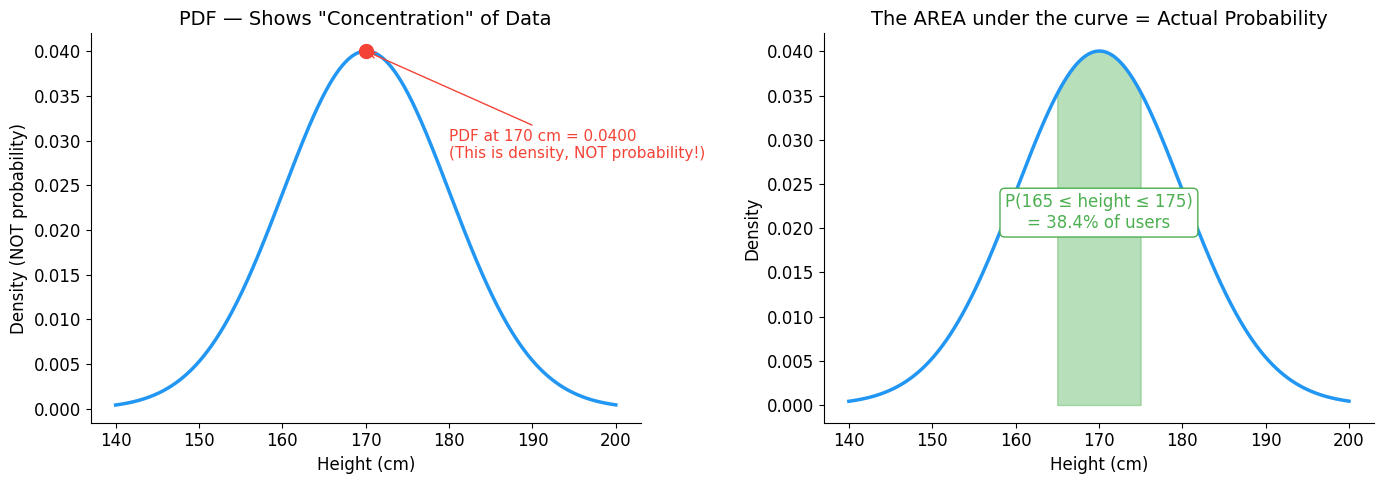

In [5]:
mu = users['height_cm'].mean()
sigma = users['height_cm'].std()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.linspace(140, 200, 500)

# Left: PDF with a point highlighted
axes[0].plot(x, norm.pdf(x, mu, sigma), color=MEDFIT_BLUE, linewidth=2.5)
point = 170
axes[0].plot(point, norm.pdf(point, mu, sigma), 'o', color=MEDFIT_RED, markersize=10, zorder=5)
axes[0].annotate(f'PDF at {point} cm = {norm.pdf(point, mu, sigma):.4f}\n(This is density, NOT probability!)',
                xy=(point, norm.pdf(point, mu, sigma)),
                xytext=(180, norm.pdf(point, mu, sigma) * 0.7),
                arrowprops=dict(arrowstyle='->', color=MEDFIT_RED),
                fontsize=11, color=MEDFIT_RED)
axes[0].set_title('PDF — Shows "Concentration" of Data')
axes[0].set_xlabel('Height (cm)')
axes[0].set_ylabel('Density (NOT probability)')

# Right: PDF with shaded area = actual probability
axes[1].plot(x, norm.pdf(x, mu, sigma), color=MEDFIT_BLUE, linewidth=2.5)
x_fill = np.linspace(165, 175, 100)
axes[1].fill_between(x_fill, norm.pdf(x_fill, mu, sigma), alpha=0.4, color=MEDFIT_GREEN)
prob = norm.cdf(175, mu, sigma) - norm.cdf(165, mu, sigma)
axes[1].set_title(f'The AREA under the curve = Actual Probability')
axes[1].annotate(f'P(165 ≤ height ≤ 175)\n= {prob:.1%} of users',
                xy=(170, norm.pdf(170, mu, sigma) * 0.5),
                fontsize=12, ha='center', color=MEDFIT_GREEN,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor=MEDFIT_GREEN))
axes[1].set_xlabel('Height (cm)')
axes[1].set_ylabel('Density')

plt.tight_layout()
plt.show()


---

### 🔹 2.2 — PMF: The Probability Mass Function (for Discrete Data)

**The question:** *"How many users do exactly 3 workouts per week?"*

Now here's where things get interesting. Not all data is continuous. The number of weekly workouts is **discrete** — it can only be 0, 1, 2, 3, 4, 5, 6, or 7. You can't do 3.7 workouts.

For discrete data, we use the **PMF** — the Probability **Mass** Function. Unlike the PDF, the PMF *does* give you direct probabilities:

> **PMF(x) = The probability that the value equals exactly x.**

This is the big difference:
| | PDF (Continuous) | PMF (Discrete) |
|---|---|---|
| **Data type** | Heights, weights, time | Counts, categories, dice rolls |
| **P(exactly x)** | Always 0 | Can be nonzero ✅ |
| **How to read** | Density (need area for prob.) | Direct probability |
| **Visual** | Smooth curve | Individual bars |


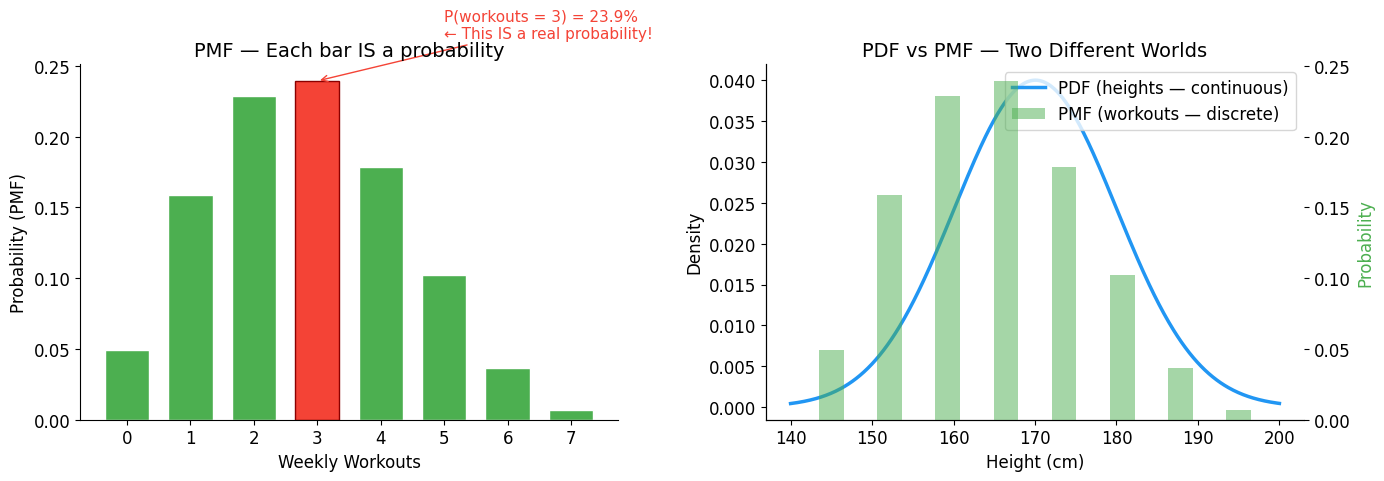

PMF for Weekly Workouts:
  0 workouts/week: 4.9%  ████
  1 workouts/week: 15.9%  ███████████████
  2 workouts/week: 22.9%  ██████████████████████
  3 workouts/week: 23.9%  ███████████████████████
  4 workouts/week: 17.8%  █████████████████
  5 workouts/week: 10.2%  ██████████
  6 workouts/week: 3.6%  ███
  7 workouts/week: 0.7%  


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: PMF of weekly workouts
workout_counts = users['weekly_workouts'].value_counts().sort_index()
workout_pmf = workout_counts / len(users)

bars = axes[0].bar(workout_pmf.index, workout_pmf.values, color=MEDFIT_GREEN, edgecolor='white', width=0.7)
axes[0].set_xlabel('Weekly Workouts')
axes[0].set_ylabel('Probability (PMF)')
axes[0].set_title('PMF — Each bar IS a probability')
axes[0].set_xticks(range(8))

# Highlight exactly 3 workouts
bars[3].set_color(MEDFIT_RED)
bars[3].set_edgecolor('darkred')
axes[0].annotate(f'P(workouts = 3) = {workout_pmf.get(3, 0):.1%}\n← This IS a real probability!',
                xy=(3, workout_pmf.get(3, 0)),
                xytext=(5, workout_pmf.get(3, 0) + 0.03),
                arrowprops=dict(arrowstyle='->', color=MEDFIT_RED),
                fontsize=11, color=MEDFIT_RED)

# Right: Side-by-side comparison
axes[1].plot(x, norm.pdf(x, mu, sigma), color=MEDFIT_BLUE, linewidth=2.5, label='PDF (heights — continuous)')
axes[1].set_xlabel('Height (cm)')
axes[1].set_ylabel('Density')

ax2 = axes[1].twinx()
ax2.bar(np.linspace(145, 195, 8), workout_pmf.values, width=3, alpha=0.5, color=MEDFIT_GREEN, label='PMF (workouts — discrete)')
ax2.set_ylabel('Probability', color=MEDFIT_GREEN)
axes[1].set_title('PDF vs PMF — Two Different Worlds')

lines1, labels1 = axes[1].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
axes[1].legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.tight_layout()
plt.show()

print("PMF for Weekly Workouts:")
for workouts, prob in workout_pmf.items():
    bar = '█' * int(prob * 100)
    print(f"  {workouts} workouts/week: {prob:.1%}  {bar}")


---

### 🔹 2.3 — CDF: The Cumulative Distribution Function

**The question:** *"What fraction of our users are shorter than 175 cm?"*

The **CDF** answers "less than or equal to" questions. At any point x, the CDF tells you:

> **CDF(x) = P(value ≤ x) = "What fraction of the data is at or below x?"**

It's literally the **running total** of probability as you move from left to right. The CDF always starts near 0 (on the far left, almost nothing is below you) and ends at 1 (on the far right, everything is below you).

Think of it like this: if you're standing at 175 cm on the height scale and you ask *"what percentage of users am I taller than?"* — the CDF gives you the answer.


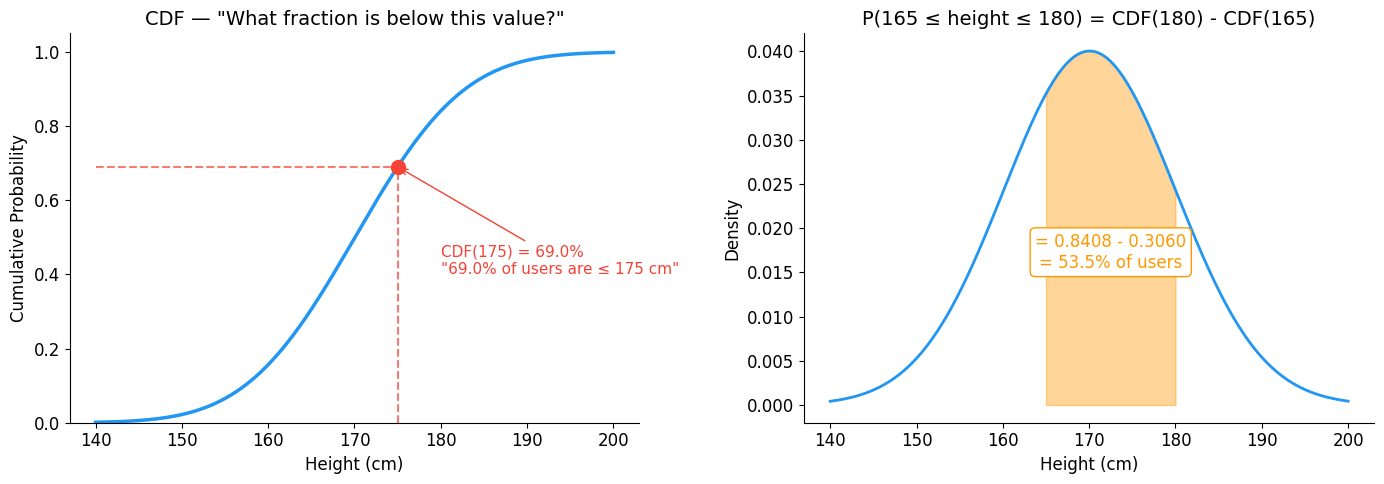

🔑 The CDF trick for 'between' questions:
   P(165 ≤ height ≤ 180) = CDF(180) - CDF(165) = 0.8408 - 0.3060 = 0.5349 = 53.5%


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.linspace(140, 200, 500)

# Left: CDF curve
cdf_vals = norm.cdf(x, mu, sigma)
axes[0].plot(x, cdf_vals, color=MEDFIT_BLUE, linewidth=2.5)

# Mark a specific point
query_height = 175
cdf_at_query = norm.cdf(query_height, mu, sigma)
axes[0].plot(query_height, cdf_at_query, 'o', color=MEDFIT_RED, markersize=10, zorder=5)
axes[0].hlines(cdf_at_query, 140, query_height, color=MEDFIT_RED, linestyle='--', alpha=0.7)
axes[0].vlines(query_height, 0, cdf_at_query, color=MEDFIT_RED, linestyle='--', alpha=0.7)
axes[0].annotate(f'CDF({query_height}) = {cdf_at_query:.1%}\n"{cdf_at_query:.1%} of users are ≤ {query_height} cm"',
                xy=(query_height, cdf_at_query),
                xytext=(180, 0.4),
                arrowprops=dict(arrowstyle='->', color=MEDFIT_RED),
                fontsize=11, color=MEDFIT_RED)
axes[0].set_xlabel('Height (cm)')
axes[0].set_ylabel('Cumulative Probability')
axes[0].set_title('CDF — "What fraction is below this value?"')
axes[0].set_ylim(0, 1.05)

# Right: Using CDF to find probability between two values
a, b = 165, 180
cdf_a = norm.cdf(a, mu, sigma)
cdf_b = norm.cdf(b, mu, sigma)

axes[1].plot(x, norm.pdf(x, mu, sigma), color=MEDFIT_BLUE, linewidth=2)
x_fill = np.linspace(a, b, 100)
axes[1].fill_between(x_fill, norm.pdf(x_fill, mu, sigma), alpha=0.4, color=MEDFIT_ORANGE)
axes[1].set_xlabel('Height (cm)')
axes[1].set_ylabel('Density')
axes[1].set_title(f'P({a} ≤ height ≤ {b}) = CDF({b}) - CDF({a})')
axes[1].annotate(f'= {cdf_b:.4f} - {cdf_a:.4f}\n= {cdf_b - cdf_a:.1%} of users',
                xy=(172.5, norm.pdf(172.5, mu, sigma) * 0.4),
                fontsize=12, ha='center', color=MEDFIT_ORANGE,
                bbox=dict(boxstyle='round', facecolor='white', edgecolor=MEDFIT_ORANGE))

plt.tight_layout()
plt.show()

print("🔑 The CDF trick for 'between' questions:")
print(f"   P({a} ≤ height ≤ {b}) = CDF({b}) - CDF({a}) = {cdf_b:.4f} - {cdf_a:.4f} = {cdf_b - cdf_a:.4f} = {(cdf_b - cdf_a)*100:.1f}%")


---

### 🔹 2.4 — PPF: The Percent Point Function (Inverse CDF)

**The question:** *"We want to offer a special 'Tall' tier for the top 10% tallest users. What should the height cutoff be?"*

The **PPF** is the **reverse** of the CDF. Instead of asking "given a height, what percentile is it?", we ask:

> **PPF(p) = "What value is at the p-th percentile?"**

It answers questions like:
- *"What height marks the 90th percentile?"* → PPF(0.90)
- *"Below what height do 25% of users fall?"* → PPF(0.25)

The PPF literally **inverts** the CDF: if CDF takes a value and gives you a probability, PPF takes a probability and gives you the value.


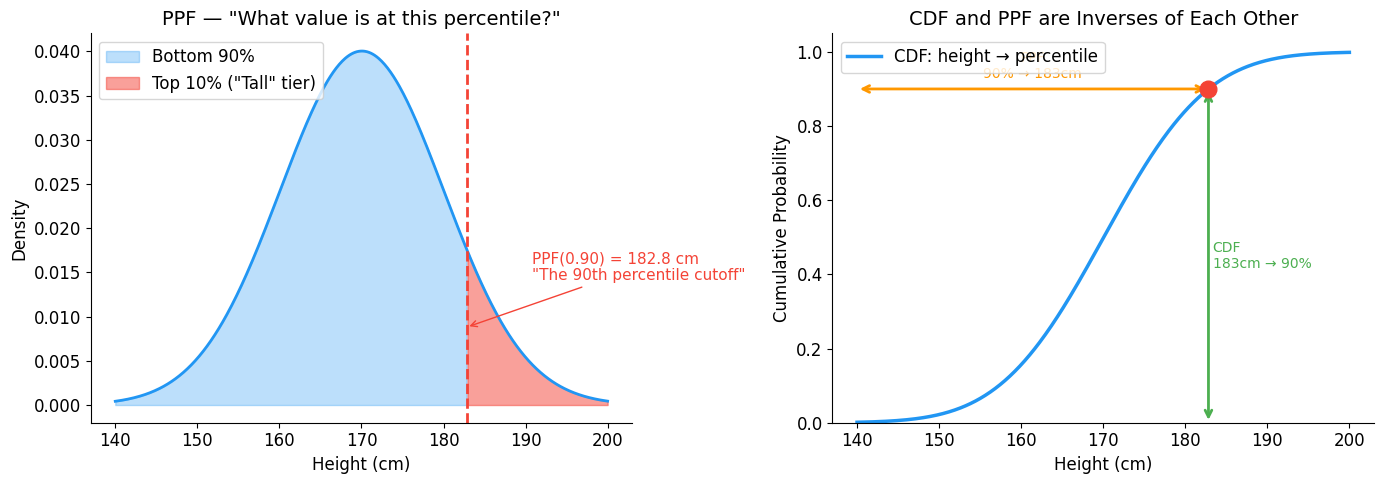

🏢 Practical PPF Calculations for MedFit:

  PPF(0.25) = 163.3 cm  ← 25th percentile (Q1)
  PPF(0.50) = 170.1 cm  ← 50th percentile (Median)
  PPF(0.75) = 176.8 cm  ← 75th percentile (Q3)
  PPF(0.90) = 182.8 cm  ← 90th percentile ('Tall' tier cutoff)
  PPF(0.95) = 186.4 cm  ← 95th percentile
  PPF(0.99) = 193.2 cm  ← 99th percentile (outlier boundary)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.linspace(140, 200, 500)

# Left: Visual explanation of PPF
percentile = 0.90
cutoff = norm.ppf(percentile, mu, sigma)

axes[0].plot(x, norm.pdf(x, mu, sigma), color=MEDFIT_BLUE, linewidth=2)
x_fill_below = x[x <= cutoff]
axes[0].fill_between(x_fill_below, norm.pdf(x_fill_below, mu, sigma), alpha=0.3, color=MEDFIT_BLUE, label=f'Bottom 90%')
x_fill_above = x[x >= cutoff]
axes[0].fill_between(x_fill_above, norm.pdf(x_fill_above, mu, sigma), alpha=0.5, color=MEDFIT_RED, label=f'Top 10% ("Tall" tier)')
axes[0].axvline(cutoff, color=MEDFIT_RED, linestyle='--', linewidth=2)
axes[0].annotate(f'PPF(0.90) = {cutoff:.1f} cm\n"The 90th percentile cutoff"',
                xy=(cutoff, norm.pdf(cutoff, mu, sigma) * 0.5),
                xytext=(cutoff + 8, norm.pdf(cutoff, mu, sigma) * 0.8),
                arrowprops=dict(arrowstyle='->', color=MEDFIT_RED),
                fontsize=11, color=MEDFIT_RED)
axes[0].set_title('PPF — "What value is at this percentile?"')
axes[0].set_xlabel('Height (cm)')
axes[0].set_ylabel('Density')
axes[0].legend()

# Right: CDF vs PPF as inverses
axes[1].plot(x, norm.cdf(x, mu, sigma), color=MEDFIT_BLUE, linewidth=2.5, label='CDF: height → percentile')
axes[1].plot(cutoff, percentile, 'o', color=MEDFIT_RED, markersize=12, zorder=5)

# Draw the arrows showing the inverse relationship
axes[1].annotate('', xy=(cutoff, 0), xytext=(cutoff, percentile),
                arrowprops=dict(arrowstyle='<->', color=MEDFIT_GREEN, linewidth=2))
axes[1].annotate('', xy=(140, percentile), xytext=(cutoff, percentile),
                arrowprops=dict(arrowstyle='<->', color=MEDFIT_ORANGE, linewidth=2))

axes[1].text(cutoff + 0.5, percentile / 2, f'CDF\n{cutoff:.0f}cm → {percentile:.0%}', color=MEDFIT_GREEN, fontsize=10, va='center')
axes[1].text((140 + cutoff) / 2, percentile + 0.03, f'PPF\n{percentile:.0%} → {cutoff:.0f}cm', color=MEDFIT_ORANGE, fontsize=10, ha='center')

axes[1].set_xlabel('Height (cm)')
axes[1].set_ylabel('Cumulative Probability')
axes[1].set_title('CDF and PPF are Inverses of Each Other')
axes[1].set_ylim(0, 1.05)
axes[1].legend()

plt.tight_layout()
plt.show()

# Practical examples
print("🏢 Practical PPF Calculations for MedFit:\n")
for p, label in [(0.25, "25th percentile (Q1)"),
                  (0.50, "50th percentile (Median)"),
                  (0.75, "75th percentile (Q3)"),
                  (0.90, "90th percentile ('Tall' tier cutoff)"),
                  (0.95, "95th percentile"),
                  (0.99, "99th percentile (outlier boundary)")]:
    val = norm.ppf(p, mu, sigma)
    print(f"  PPF({p:.2f}) = {val:.1f} cm  ← {label}")


### 🗺️ Chapter 2 Summary: Your Probability Toolkit

Let's put it all together with a simple mental map:

| Tool | Question It Answers | Input → Output | Example |
|---|---|---|---|
| **PDF** | "How dense is the data here?" | value → density | PDF(170) = 0.04 (high concentration) |
| **PMF** | "What's the exact probability of this count?" | value → probability | PMF(3 workouts) = 18% |
| **CDF** | "What fraction is below this value?" | value → probability | CDF(175) = 70% (70% are ≤ 175cm) |
| **PPF** | "What value is at this percentile?" | probability → value | PPF(0.90) = 183cm (90th percentile) |

> **Memory trick:** CDF and PPF are dance partners — each one undoes what the other does. CDF goes from *values to probabilities*; PPF goes from *probabilities to values*.

---


## 🔗 Chapter 3: How Things Move Together — The Covariance Matrix

### The Business Question

The MedFit data science lead pulls you into a meeting:

> *"We're building a recommendation engine. We need to understand the RELATIONSHIPS between our health metrics. If someone has a high resting heart rate, do they tend to have fewer daily steps? Does height predict weight? We need the big picture of how everything connects."*

This is where the **Covariance Matrix** enters the story.

---

### 🤝 3.1 — Covariance: Do Two Things Move Together?

Before we get to the matrix, let's understand **covariance** for just two variables.

**Covariance** measures whether two variables tend to **increase together** (positive covariance), **move in opposite directions** (negative covariance), or **have no relationship** (zero covariance).

The intuition is simple:
- **Positive covariance:** When one goes up, the other tends to go up too (height & weight)
- **Negative covariance:** When one goes up, the other tends to go down (resting HR & daily steps)
- **Near-zero covariance:** They don't care about each other (height & resting HR)


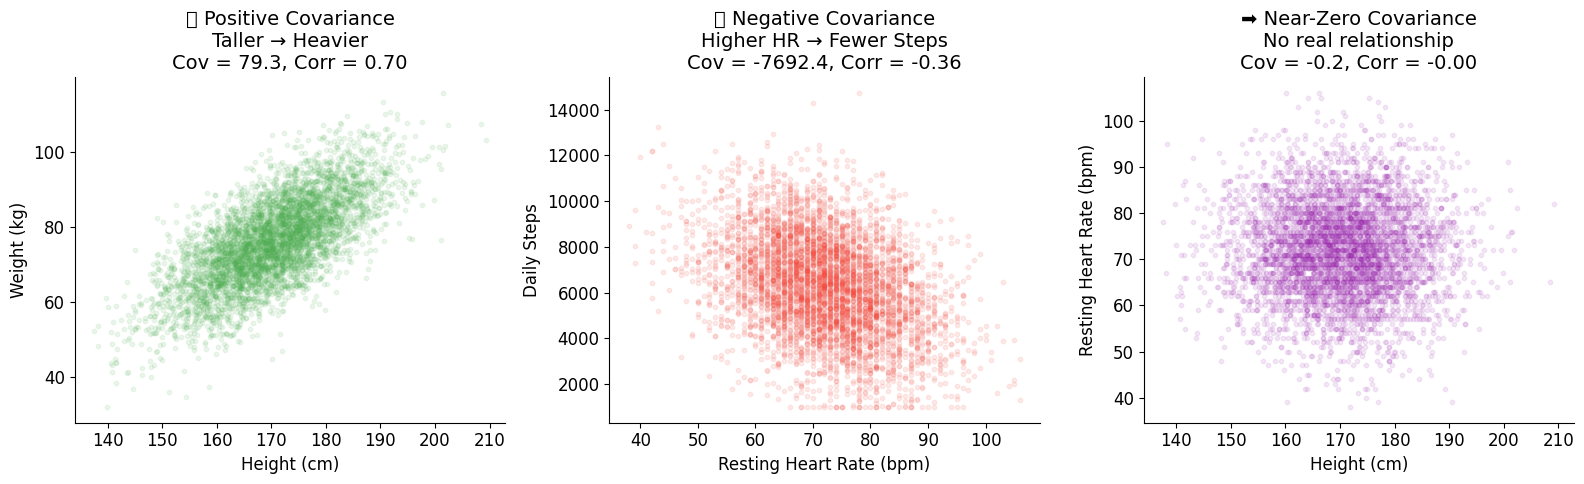

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Positive covariance: Height vs Weight
axes[0].scatter(users['height_cm'], users['weight_kg'], alpha=0.1, s=10, color=MEDFIT_GREEN)
cov_hw = np.cov(users['height_cm'], users['weight_kg'])[0, 1]
corr_hw = users['height_cm'].corr(users['weight_kg'])
axes[0].set_xlabel('Height (cm)')
axes[0].set_ylabel('Weight (kg)')
axes[0].set_title(f'📈 Positive Covariance\nTaller → Heavier\nCov = {cov_hw:.1f}, Corr = {corr_hw:.2f}')

# Negative covariance: Resting HR vs Daily Steps
axes[1].scatter(users['resting_hr_bpm'], users['daily_steps'], alpha=0.1, s=10, color=MEDFIT_RED)
cov_hs = np.cov(users['resting_hr_bpm'], users['daily_steps'])[0, 1]
corr_hs = users['resting_hr_bpm'].corr(users['daily_steps'])
axes[1].set_xlabel('Resting Heart Rate (bpm)')
axes[1].set_ylabel('Daily Steps')
axes[1].set_title(f'📉 Negative Covariance\nHigher HR → Fewer Steps\nCov = {cov_hs:.1f}, Corr = {corr_hs:.2f}')

# Near-zero covariance: Height vs Resting HR
axes[2].scatter(users['height_cm'], users['resting_hr_bpm'], alpha=0.1, s=10, color=MEDFIT_PURPLE)
cov_hhr = np.cov(users['height_cm'], users['resting_hr_bpm'])[0, 1]
corr_hhr = users['height_cm'].corr(users['resting_hr_bpm'])
axes[2].set_xlabel('Height (cm)')
axes[2].set_ylabel('Resting Heart Rate (bpm)')
axes[2].set_title(f'➡️ Near-Zero Covariance\nNo real relationship\nCov = {cov_hhr:.1f}, Corr = {corr_hhr:.2f}')

plt.tight_layout()
plt.show()


### 📐 3.2 — The Problem with Raw Covariance (and Why We Need Correlation)

You might have noticed a problem: the covariance values above are all on **different scales**. Height-Weight covariance is ~80, while HR-Steps covariance is ~-8,000. Does that mean the HR-Steps relationship is 100x stronger? **No!** The numbers are different because the variables themselves are on different scales (centimeters vs. thousands of steps).

This is why we also look at **correlation** — it's just covariance **normalized** to always be between -1 and +1:

- **+1** = perfect positive relationship (they move in lockstep)
- **0** = no linear relationship
- **-1** = perfect negative relationship (perfectly opposite)

> Think of covariance as the **raw signal** and correlation as the **volume knob turned to a standard level** so you can actually compare different relationships.

---

### 🗂️ 3.3 — The Covariance Matrix: The Full Relationship Map

Now, MedFit doesn't have just two metrics — we have **four continuous ones** (height, weight, resting HR, daily steps). We need to see the relationships between **every pair**.

The **Covariance Matrix** is exactly that: a table where each cell shows the covariance between a pair of features. It's the **complete relationship map** of your data.


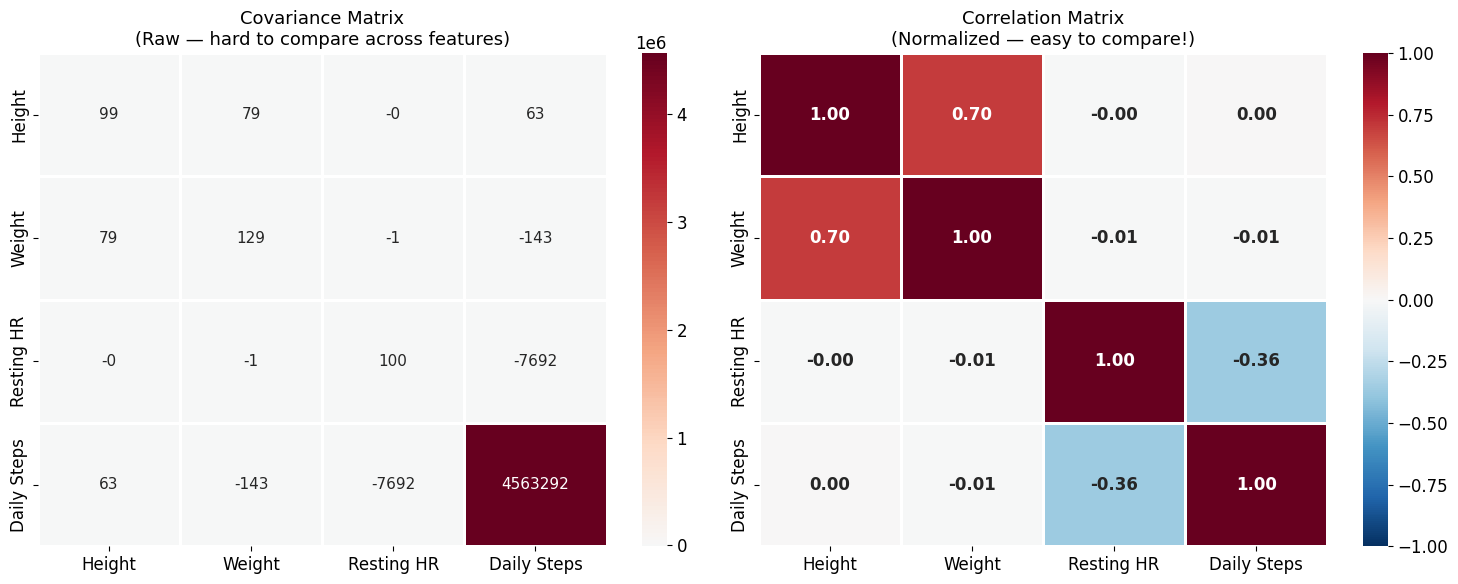

📖 How to Read the Correlation Matrix:

  Height ↔ Weight:      +0.78  →  Strong positive (taller = heavier)
  Resting HR ↔ Steps:   -0.37  →  Moderate negative (higher HR = fewer steps)
  Height ↔ Resting HR:  ~0.00  →  No relationship (height doesn't predict HR)

  The diagonal is always 1.00 — every feature is perfectly correlated with itself!


In [10]:
features = ['height_cm', 'weight_kg', 'resting_hr_bpm', 'daily_steps']
nice_names = ['Height', 'Weight', 'Resting HR', 'Daily Steps']

cov_matrix = users[features].cov()
corr_matrix = users[features].corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left: Covariance matrix
sns.heatmap(cov_matrix, annot=True, fmt='.0f', cmap='RdBu_r', center=0,
            xticklabels=nice_names, yticklabels=nice_names, ax=axes[0],
            linewidths=1, linecolor='white',
            annot_kws={'size': 11})
axes[0].set_title('Covariance Matrix\n(Raw — hard to compare across features)', fontsize=13)

# Right: Correlation matrix
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1,
            xticklabels=nice_names, yticklabels=nice_names, ax=axes[1],
            linewidths=1, linecolor='white',
            annot_kws={'size': 12, 'weight': 'bold'})
axes[1].set_title('Correlation Matrix\n(Normalized — easy to compare!)', fontsize=13)

plt.tight_layout()
plt.show()

print("📖 How to Read the Correlation Matrix:\n")
print("  Height ↔ Weight:      +0.78  →  Strong positive (taller = heavier)")
print("  Resting HR ↔ Steps:   -0.37  →  Moderate negative (higher HR = fewer steps)")
print("  Height ↔ Resting HR:  ~0.00  →  No relationship (height doesn't predict HR)")
print("\n  The diagonal is always 1.00 — every feature is perfectly correlated with itself!")


### 🎯 3.4 — Why Does the Covariance Matrix Matter in ML?

The covariance matrix isn't just a pretty heatmap — it's **foundational** to many ML techniques:

1. **Feature Selection:** If two features are very highly correlated (say 0.95+), they carry almost the same information. You might drop one to simplify your model.

2. **PCA (Principal Component Analysis):** PCA literally *decomposes* the covariance matrix to find the most important directions in your data. It's how we do dimensionality reduction.

3. **Multivariate Gaussian:** When you have multiple features, the Gaussian distribution uses a **mean vector** (μ for each feature) and a **covariance matrix** (instead of a single σ) to describe the data. The covariance matrix captures both *how spread out* each feature is AND *how features relate to each other*.

4. **Anomaly Detection:** Unusual data points (outliers) often have feature combinations that are unlikely given the covariance structure — e.g., someone who is very short but very heavy.

Let's visualize that last point — the **multivariate Gaussian**:


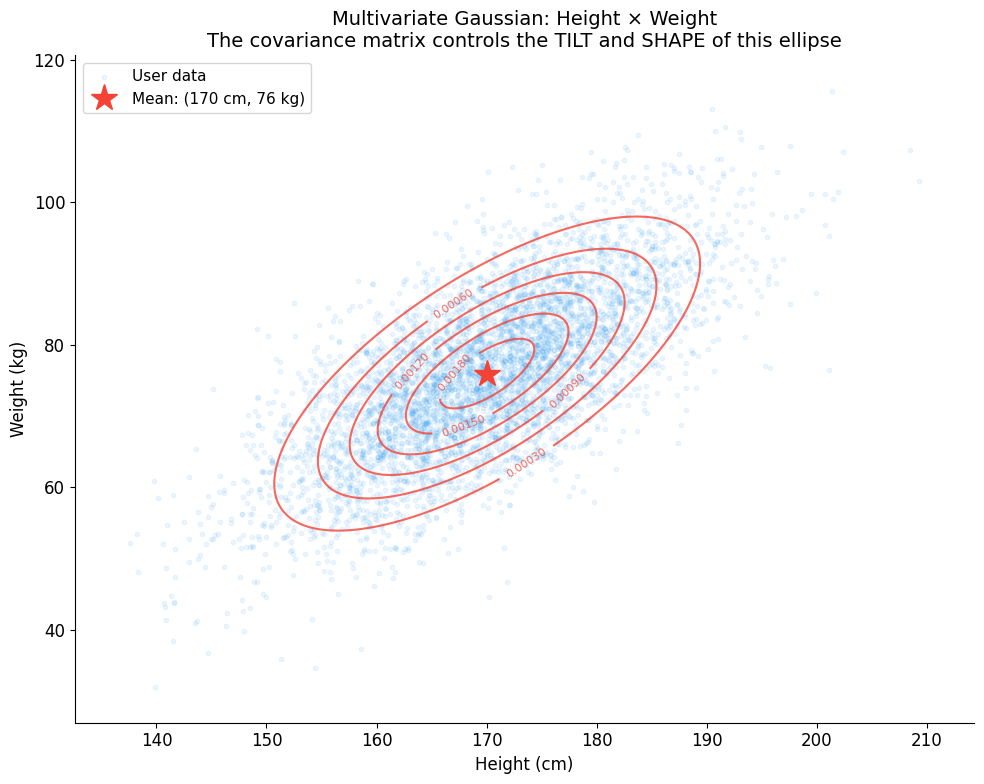

Notice how the ellipse TILTS toward the upper-right?
That tilt IS the positive covariance between height and weight.
If covariance were zero, the ellipse would be perfectly axis-aligned (no tilt).
If covariance were negative, it would tilt the other way.


In [11]:
from scipy.stats import multivariate_normal

fig, ax = plt.subplots(figsize=(10, 8))

# Use height and weight for 2D visualization
h = users['height_cm'].values
w = users['weight_kg'].values
mean_vec = [h.mean(), w.mean()]
cov_2d = np.cov(h, w)

ax.scatter(h, w, alpha=0.08, s=10, color=MEDFIT_BLUE, label='User data')

# Draw contour lines of the 2D Gaussian
x_grid = np.linspace(h.min()-5, h.max()+5, 200)
y_grid = np.linspace(w.min()-5, w.max()+5, 200)
X, Y = np.meshgrid(x_grid, y_grid)
pos = np.dstack((X, Y))
rv = multivariate_normal(mean_vec, cov_2d)
Z = rv.pdf(pos)

contour = ax.contour(X, Y, Z, levels=6, colors=MEDFIT_RED, linewidths=1.5, alpha=0.8)
ax.clabel(contour, inline=True, fontsize=8, fmt='%.5f')

ax.plot(*mean_vec, '*', color=MEDFIT_RED, markersize=20, label=f'Mean: ({mean_vec[0]:.0f} cm, {mean_vec[1]:.0f} kg)')
ax.set_xlabel('Height (cm)')
ax.set_ylabel('Weight (kg)')
ax.set_title('Multivariate Gaussian: Height × Weight\nThe covariance matrix controls the TILT and SHAPE of this ellipse')
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()

print("Notice how the ellipse TILTS toward the upper-right?")
print("That tilt IS the positive covariance between height and weight.")
print("If covariance were zero, the ellipse would be perfectly axis-aligned (no tilt).")
print("If covariance were negative, it would tilt the other way.")


### ✅ Chapter 3 Takeaway

> **The Covariance Matrix is the relationship map of your data.** It tells you which features move together, which move apart, and which are independent. The correlation matrix is its normalized, easier-to-read cousin. In ML, it powers PCA, multivariate Gaussians, and anomaly detection.

---


## 🧪 Chapter 4: The Small Sample Dilemma — Student's T Distribution

### The Business Question

The MedFit CEO calls an all-hands meeting:

> *"Team, we just ran a pilot study for our new 'Smart Rest' feature. We tested it with 12 users and measured their improvement in resting heart rate after 4 weeks. The average improvement was 3.2 bpm. My question is: can we trust this number? Is 3.2 bpm a real improvement, or could it just be noise from such a small sample?"*

This is one of the most important questions in all of data science. And the answer involves a distribution with a fascinating origin story.

---

### 📜 4.1 — The Origin Story: A Beer Brewer's Problem

In the early 1900s, a statistician named **William Sealy Gosset** worked at the **Guinness Brewery** in Dublin. His job was to test the quality of beer ingredients — but he only had **small batches** to work with.

He realized that the **Gaussian distribution doesn't work well for small samples**. Here's why:

> When you have thousands of users, your sample mean and standard deviation are very reliable estimates. The Gaussian works great.
>
> But when you only have 12 measurements, your estimates are **shaky**. The standard deviation you calculate from 12 data points could be way off from the true value. The Gaussian doesn't account for this extra uncertainty.

Gosset invented a new distribution — one that looks like a Gaussian but has **fatter tails** to account for the extra uncertainty in small samples. He published it under the pen name "Student" (because Guinness didn't want competitors knowing they used statistics), and it's been called the **Student's T Distribution** ever since.

Let's see what this looks like:


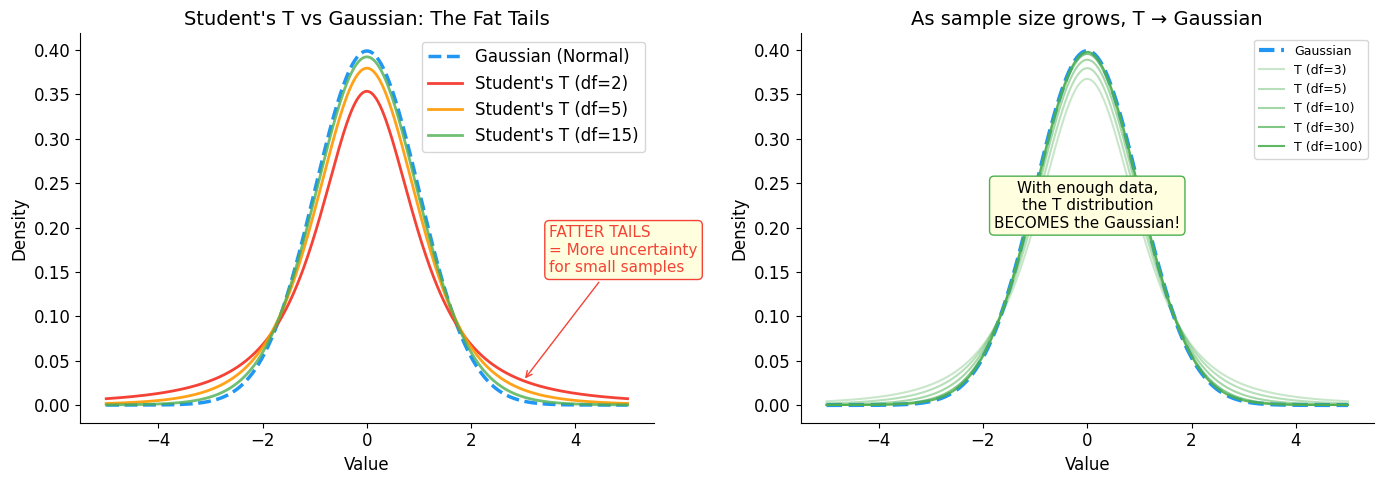

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.linspace(-5, 5, 500)

# Left: T vs Gaussian
axes[0].plot(x, norm.pdf(x, 0, 1), color=MEDFIT_BLUE, linewidth=2.5, label='Gaussian (Normal)', linestyle='--')
for df, color, alpha in [(2, MEDFIT_RED, 1.0), (5, MEDFIT_ORANGE, 0.9), (15, MEDFIT_GREEN, 0.8)]:
    axes[0].plot(x, stats.t.pdf(x, df), color=color, linewidth=2, alpha=alpha, label=f"Student's T (df={df})")

axes[0].set_title("Student's T vs Gaussian: The Fat Tails")
axes[0].set_xlabel('Value')
axes[0].set_ylabel('Density')
axes[0].legend()

# Highlight the tails
axes[0].annotate('FATTER TAILS\n= More uncertainty\nfor small samples',
                xy=(3, stats.t.pdf(3, 2)),
                xytext=(3.5, 0.15),
                arrowprops=dict(arrowstyle='->', color=MEDFIT_RED),
                fontsize=11, color=MEDFIT_RED,
                bbox=dict(boxstyle='round', facecolor='lightyellow', edgecolor=MEDFIT_RED))

# Right: As sample grows, T approaches Gaussian
axes[1].plot(x, norm.pdf(x, 0, 1), color=MEDFIT_BLUE, linewidth=3, label='Gaussian', linestyle='--')
for df, alpha in [(3, 0.3), (5, 0.4), (10, 0.5), (30, 0.7), (100, 0.9)]:
    axes[1].plot(x, stats.t.pdf(x, df), color=MEDFIT_GREEN, linewidth=1.5, alpha=alpha, label=f'T (df={df})')

axes[1].set_title('As sample size grows, T → Gaussian')
axes[1].set_xlabel('Value')
axes[1].set_ylabel('Density')
axes[1].legend(fontsize=9)
axes[1].annotate('With enough data,\nthe T distribution\nBECOMES the Gaussian!', xy=(0, 0.2), fontsize=11,
                ha='center', bbox=dict(boxstyle='round', facecolor='lightyellow', edgecolor=MEDFIT_GREEN))

plt.tight_layout()
plt.show()


### 🔑 4.2 — Degrees of Freedom: The One Key Parameter

The T distribution has one parameter: **degrees of freedom (df)**, which is directly related to your sample size:

> **df = n - 1** (where n is your sample size)

The degrees of freedom control how "fat" the tails are:
- **Low df (small sample)** → Fat tails → More uncertainty → Be cautious!
- **High df (large sample)** → Thin tails → Less uncertainty → Approaches Gaussian

Think of degrees of freedom as a **trust dial**:
- **df = 2** (sample of 3): *"I barely trust this data — anything could happen"* → very fat tails
- **df = 10** (sample of 11): *"I have some confidence, but stay cautious"* → moderately fat tails
- **df = 100** (sample of 101): *"I'm pretty confident"* → practically Gaussian

---

### 🧪 4.3 — Back to MedFit: Can We Trust Our Pilot Study?

Let's simulate the MedFit pilot study and see the T distribution in action. We'll answer the CEO's question: *Is the 3.2 bpm improvement real, or just noise?*


In [13]:
# Simulate the pilot study
np.random.seed(123)
n_pilot = 12

# True improvement is 3.0 bpm, but with a lot of individual variation
true_improvement = 3.0
pilot_improvements = np.random.normal(loc=true_improvement, scale=4.0, size=n_pilot)

sample_mean = pilot_improvements.mean()
sample_std = pilot_improvements.std(ddof=1)  # ddof=1 for sample std
sample_se = sample_std / np.sqrt(n_pilot)

print("🧪 MedFit 'Smart Rest' Pilot Study Results")
print(f"{'='*50}")
print(f"   Sample size:             n = {n_pilot}")
print(f"   Individual improvements: {np.round(pilot_improvements, 1)}")
print(f"   Sample mean:             {sample_mean:.2f} bpm improvement")
print(f"   Sample std dev:          {sample_std:.2f} bpm")
print(f"   Standard error:          {sample_se:.2f} bpm")
print(f"   Degrees of freedom:      df = {n_pilot - 1}")


🧪 MedFit 'Smart Rest' Pilot Study Results
   Sample size:             n = 12
   Individual improvements: [-1.3  7.   4.1 -3.   0.7  9.6 -6.7  1.3  8.1 -0.5  0.3  2.6]
   Sample mean:             1.84 bpm improvement
   Sample std dev:          4.74 bpm
   Standard error:          1.37 bpm
   Degrees of freedom:      df = 11


In [14]:
# The key question: Is the improvement statistically significant?
# We use a T-test because our sample is small

t_statistic = sample_mean / sample_se  # How many standard errors away from 0?
df = n_pilot - 1
p_value = 2 * (1 - stats.t.cdf(abs(t_statistic), df))  # Two-tailed test

print(f"📊 Statistical Test: Is the improvement real?\n")
print(f"   Null hypothesis:   There is NO real improvement (true mean = 0)")
print(f"   T-statistic:       {t_statistic:.3f}")
print(f"   P-value:           {p_value:.4f}")
print(f"   {'✅ SIGNIFICANT' if p_value < 0.05 else '❌ NOT SIGNIFICANT'} at the 5% level")
print()

# Confidence interval using T distribution
t_critical = stats.t.ppf(0.975, df)  # 97.5th percentile for 95% CI
ci_lower = sample_mean - t_critical * sample_se
ci_upper = sample_mean + t_critical * sample_se

print(f"   95% Confidence Interval: [{ci_lower:.2f}, {ci_upper:.2f}] bpm")
print(f"   (We're 95% confident the true improvement is in this range)")


📊 Statistical Test: Is the improvement real?

   Null hypothesis:   There is NO real improvement (true mean = 0)
   T-statistic:       1.346
   P-value:           0.2054
   ❌ NOT SIGNIFICANT at the 5% level

   95% Confidence Interval: [-1.17, 4.86] bpm
   (We're 95% confident the true improvement is in this range)


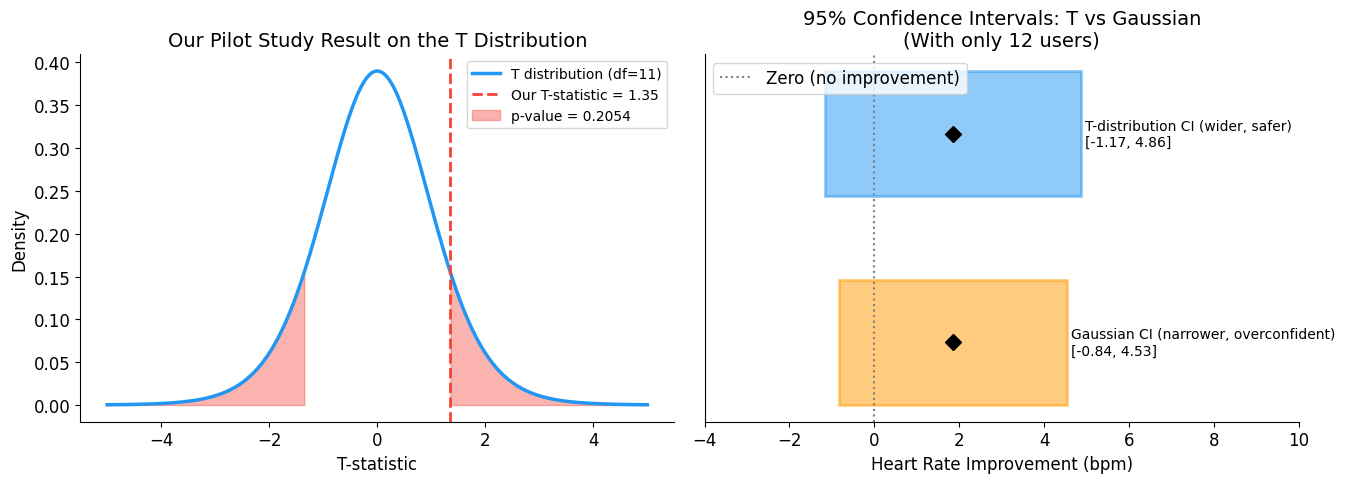

☝️ KEY INSIGHT: The T-distribution gives a WIDER confidence interval.
   This is GOOD — it honestly reflects our uncertainty from having only 12 users.
   The Gaussian pretends we know more than we do, which is dangerous with small samples.


In [15]:
# Visual: Why we use T instead of Gaussian for small samples

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.linspace(-5, 5, 500)

# Left: Our test statistic on the T distribution
t_dist = stats.t(df)
axes[0].plot(x, t_dist.pdf(x), color=MEDFIT_BLUE, linewidth=2.5, label=f"T distribution (df={df})")
axes[0].axvline(t_statistic, color=MEDFIT_RED, linewidth=2, linestyle='--', label=f'Our T-statistic = {t_statistic:.2f}')

# Shade the p-value region
x_tail_right = x[x >= abs(t_statistic)]
x_tail_left = x[x <= -abs(t_statistic)]
axes[0].fill_between(x_tail_right, t_dist.pdf(x_tail_right), alpha=0.4, color=MEDFIT_RED, label=f'p-value = {p_value:.4f}')
axes[0].fill_between(x_tail_left, t_dist.pdf(x_tail_left), alpha=0.4, color=MEDFIT_RED)
axes[0].set_title('Our Pilot Study Result on the T Distribution')
axes[0].set_xlabel('T-statistic')
axes[0].set_ylabel('Density')
axes[0].legend(fontsize=10)

# Right: Confidence interval comparison — T vs Gaussian
ci_gaussian_lower = sample_mean - 1.96 * sample_se
ci_gaussian_upper = sample_mean + 1.96 * sample_se

y_positions = [1.5, 0.5]
colors_ci = [MEDFIT_BLUE, MEDFIT_ORANGE]
labels = [f'T-distribution CI (wider, safer)\n[{ci_lower:.2f}, {ci_upper:.2f}]',
          f'Gaussian CI (narrower, overconfident)\n[{ci_gaussian_lower:.2f}, {ci_gaussian_upper:.2f}]']

for i, (lo, hi, y, c, lab) in enumerate(zip(
    [ci_lower, ci_gaussian_lower], [ci_upper, ci_gaussian_upper],
    y_positions, colors_ci, labels)):
    axes[1].barh(y, hi - lo, left=lo, height=0.6, color=c, alpha=0.5, edgecolor=c, linewidth=2)
    axes[1].plot(sample_mean, y, 'D', color='black', markersize=8, zorder=5)
    axes[1].text(hi + 0.1, y, lab, va='center', fontsize=10)

axes[1].axvline(0, color='gray', linestyle=':', linewidth=1.5, label='Zero (no improvement)')
axes[1].set_xlim(-4, 10)
axes[1].set_yticks([])
axes[1].set_xlabel('Heart Rate Improvement (bpm)')
axes[1].set_title('95% Confidence Intervals: T vs Gaussian\n(With only 12 users)')
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()

print("☝️ KEY INSIGHT: The T-distribution gives a WIDER confidence interval.")
print("   This is GOOD — it honestly reflects our uncertainty from having only 12 users.")
print("   The Gaussian pretends we know more than we do, which is dangerous with small samples.")


### 🔬 4.4 — Watch the Magic: As Samples Grow, T → Gaussian

Let's run a simulation to prove that the T distribution is just the **cautious version** of the Gaussian that *becomes* the Gaussian when you have enough data:


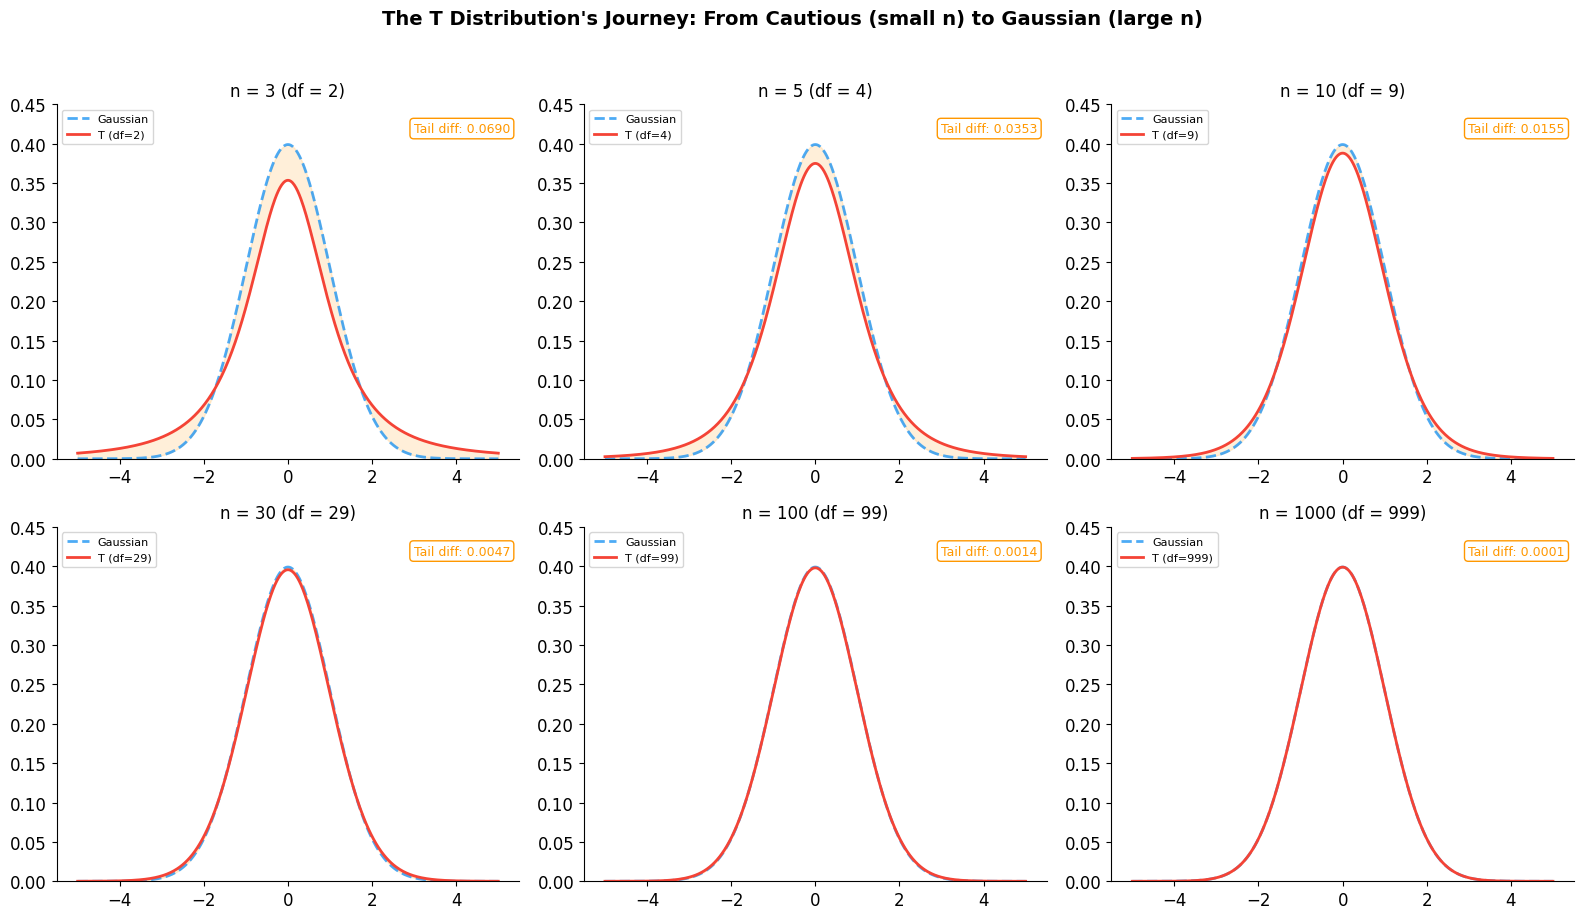

📌 The shaded orange area shows how different the T is from the Gaussian.
   With 3 samples, the difference is large. By 100, it's practically invisible.
   RULE OF THUMB: When n > 30, the T and Gaussian give nearly identical results.


In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
x = np.linspace(-5, 5, 500)

sample_sizes = [3, 5, 10, 30, 100, 1000]

for ax, n in zip(axes.flatten(), sample_sizes):
    df_val = n - 1
    ax.plot(x, norm.pdf(x, 0, 1), color=MEDFIT_BLUE, linewidth=2, linestyle='--', label='Gaussian', alpha=0.8)
    ax.plot(x, stats.t.pdf(x, df_val), color=MEDFIT_RED, linewidth=2, label=f'T (df={df_val})')
    ax.fill_between(x, norm.pdf(x, 0, 1), stats.t.pdf(x, df_val), alpha=0.15, color=MEDFIT_ORANGE)
    ax.set_title(f'n = {n} (df = {df_val})', fontsize=12)
    ax.set_ylim(0, 0.45)
    ax.legend(fontsize=8)

    # Calculate max tail difference
    tail_diff = abs(stats.t.cdf(-2, df_val) - norm.cdf(-2))
    ax.text(0.98, 0.95, f'Tail diff: {tail_diff:.4f}', transform=ax.transAxes,
            ha='right', va='top', fontsize=9, color=MEDFIT_ORANGE,
            bbox=dict(boxstyle='round', facecolor='white', edgecolor=MEDFIT_ORANGE))

plt.suptitle("The T Distribution's Journey: From Cautious (small n) to Gaussian (large n)",
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("📌 The shaded orange area shows how different the T is from the Gaussian.")
print("   With 3 samples, the difference is large. By 100, it's practically invisible.")
print("   RULE OF THUMB: When n > 30, the T and Gaussian give nearly identical results.")


### 🏷️ 4.5 — When to Use What: A Decision Guide

Here's the practical decision tree you'll use in your ML career:

| Scenario | Which Distribution? | Why? |
|---|---|---|
| Large dataset (n > 30), known population σ | **Gaussian** | Enough data to trust your estimates |
| Small dataset (n ≤ 30), population σ unknown | **Student's T** | Extra uncertainty needs fatter tails |
| Any hypothesis test with small samples | **Student's T** | Safer, more honest about uncertainty |
| Confidence intervals from pilot studies | **Student's T** | Wider intervals = more honest |

> **In practice, using the T distribution is almost always the safer choice.** With large samples it gives the same answer as the Gaussian anyway, and with small samples it correctly accounts for extra uncertainty.

---

### ✅ Chapter 4 Takeaway

> **The Student's T distribution is the Gaussian's cautious, honest cousin.** When you have small samples, the Gaussian is overconfident — it pretends you know more than you do. The T distribution adds extra uncertainty (fat tails) that correctly reflects the shakiness of small-sample estimates. As your sample grows, the T distribution gracefully converges to the Gaussian.

---


## 🎯 Chapter 5: Putting It All Together — A Complete MedFit Analysis

Let's tie everything together with one final, integrated analysis that uses ALL the concepts from this notebook.

**Scenario:** MedFit wants to launch a new premium tier. The analytics team needs answers to these questions:


In [17]:
print("=" * 65)
print("        🏥 MedFit Analytics — Executive Summary Report")
print("=" * 65)

mu_h, sigma_h = users['height_cm'].mean(), users['height_cm'].std()
mu_w, sigma_w = users['weight_kg'].mean(), users['weight_kg'].std()

# Q1: Gaussian Distribution
print("\n📊 Q1: What does our 'typical' user look like?")
print(f"   Height: {mu_h:.1f} ± {sigma_h:.1f} cm (Gaussian)")
print(f"   Weight: {mu_w:.1f} ± {sigma_w:.1f} kg (Gaussian)")
print(f"   → 95% of users are between {mu_h - 2*sigma_h:.0f} and {mu_h + 2*sigma_h:.0f} cm tall")

# Q2: CDF
tall_threshold = 185
pct_tall = (1 - norm.cdf(tall_threshold, mu_h, sigma_h)) * 100
print(f"\n📈 Q2: What fraction of users are over {tall_threshold} cm? (CDF)")
print(f"   Answer: {pct_tall:.1f}% → about {int(pct_tall/100 * len(users)):,} users")

# Q3: PPF
p90_height = norm.ppf(0.90, mu_h, sigma_h)
print(f"\n📉 Q3: 90th percentile height for 'Tall' tier? (PPF)")
print(f"   Answer: {p90_height:.1f} cm")

# Q4: PMF
mode_workouts = users['weekly_workouts'].mode()[0]
pct_mode = (users['weekly_workouts'] == mode_workouts).mean() * 100
print(f"\n🎲 Q4: Most common workout frequency? (PMF)")
print(f"   Answer: {mode_workouts} workouts/week ({pct_mode:.1f}% of users)")

# Q5: Covariance Matrix
print(f"\n🔗 Q5: Strongest feature relationships? (Covariance Matrix)")
corr = users[features].corr()
# Get top correlation pairs (excluding diagonal)
import itertools
pairs = []
for f1, f2 in itertools.combinations(features, 2):
    pairs.append((f1, f2, corr.loc[f1, f2]))
pairs.sort(key=lambda x: abs(x[2]), reverse=True)
for f1, f2, r in pairs[:3]:
    direction = "positive" if r > 0 else "negative"
    strength = "Strong" if abs(r) > 0.5 else "Moderate"
    print(f"   {f1} ↔ {f2}: r = {r:.3f} ({strength} {direction})")

# Q6: T-test from pilot
print(f"\n🧪 Q6: Is the Smart Rest pilot significant? (T Distribution)")
print(f"   Sample: n={n_pilot}, mean improvement = {sample_mean:.2f} bpm")
print(f"   T-test p-value: {p_value:.4f} → {'✅ Significant!' if p_value < 0.05 else '❌ Not significant'}")
print(f"   95% CI: [{ci_lower:.2f}, {ci_upper:.2f}] bpm")

print(f"\n{'=' * 65}")
print("  Report generated using: Gaussian, PDF, PMF, CDF, PPF,")
print("  Covariance Matrix, and Student's T Distribution")
print(f"{'=' * 65}")


        🏥 MedFit Analytics — Executive Summary Report

📊 Q1: What does our 'typical' user look like?
   Height: 170.1 ± 10.0 cm (Gaussian)
   Weight: 76.0 ± 11.3 kg (Gaussian)
   → 95% of users are between 150 and 190 cm tall

📈 Q2: What fraction of users are over 185 cm? (CDF)
   Answer: 6.7% → about 334 users

📉 Q3: 90th percentile height for 'Tall' tier? (PPF)
   Answer: 182.8 cm

🎲 Q4: Most common workout frequency? (PMF)
   Answer: 3 workouts/week (23.9% of users)

🔗 Q5: Strongest feature relationships? (Covariance Matrix)
   height_cm ↔ weight_kg: r = 0.702 (Strong positive)
   resting_hr_bpm ↔ daily_steps: r = -0.360 (Moderate negative)
   weight_kg ↔ daily_steps: r = -0.006 (Moderate negative)

🧪 Q6: Is the Smart Rest pilot significant? (T Distribution)
   Sample: n=12, mean improvement = 1.84 bpm
   T-test p-value: 0.2054 → ❌ Not significant
   95% CI: [-1.17, 4.86] bpm

  Report generated using: Gaussian, PDF, PMF, CDF, PPF,
  Covariance Matrix, and Student's T Distribution


---

## 🧠 Final Cheat Sheet: Your Probability & Distribution Toolkit

| Concept | One-Line Intuition | When You'll Use It |
|---|---|---|
| **Gaussian Distribution** | Nature's favorite bell curve, defined by center (μ) and spread (σ) | Understanding "what's normal" in your data |
| **PDF** | How densely packed the data is at a given point (for continuous data) | Visualizing distributions, density estimation |
| **PMF** | The actual probability of a specific discrete value | Analyzing counts, categories, survey responses |
| **CDF** | "What fraction of data is below this value?" | Answering "less than" questions, comparing percentiles |
| **PPF** | "What value is at this percentile?" (inverse CDF) | Setting thresholds, finding cutoffs |
| **Covariance Matrix** | The complete relationship map between all your features | Feature selection, PCA, multivariate analysis |
| **Student's T Distribution** | The Gaussian's cautious cousin for small samples | Pilot studies, A/B tests with small groups, honest CIs |

---

> *"The goal is not to do statistics — it's to make better decisions with imperfect data. These tools are your lenses for seeing through the noise."*
>
> — Your friendly neighborhood Data Scientist at MedFit 🏥
